In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset,WeightedRandomSampler
from torch.nn.utils.rnn import pad_sequence
from google.colab import drive
from collections import Counter
from sklearn.metrics import confusion_matrix,classification_report
torch.manual_seed(42)

In [ ]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

In [ ]:

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load data

In [ ]:
test_df = pd.read_csv('/content/drive/MyDrive/Assignment_2_Dataset/Task 3/Data 3/test.csv')
train_df = pd.read_csv('/content/drive/MyDrive/Assignment_2_Dataset/Task 3/Data 3/train.csv')
GLOVE_PATH='/content/drive/MyDrive/Assignment_2_Dataset/Task 3/glove.6B.200d.txt'


#PreProcess Tweet

In [ ]:
import re
import unicodedata
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))
def Preprocess(text):

    text = text.lower()

    text = re.sub(r'&[a-z]+;', '', text)

    text = re.sub(r'(@[A-Za-z0-9_]+)|(https?://[^\s]+)', '', text)

    text = [word for word in text.split() if word not in stop_words]
    text = " ".join(text)

    return text

In [ ]:

test_df['tweet']=test_df['tweet'].apply(Preprocess)
train_df['tweet']=train_df['tweet'].apply(Preprocess)

test_df['sentiment']= test_df['sentiment'].map({'Positive':0,'Negative':1})
train_df['sentiment']= train_df['sentiment'].map({'Positive':0,'Negative':1})

In [ ]:
pos_sample= train_df['sentiment'].value_counts()[0]
neg_sample = train_df['sentiment'].value_counts()[1]
pos_sample,neg_sample

(np.int64(404), np.int64(5196))

In [ ]:
test_df,train_df

(         id  sentiment                                              tweet
 0     12203          1  eeeee love paydays lol great thing youniquepla...
 1     14628          1  yoga staeraa #yoga #exercise #health #healing ...
 2     25641          1                          #strong #weak #happy #hea
 3     26507          1  happy pharrell williams #pharrellwilliams lyri...
 4     20805          1  sick #badger #dorset wife brought gloves blank...
 ...     ...        ...                                                ...
 1395  25549          1  treasures #wisconsin libraries museums histori...
 1396   8078          1                                 cant wait tomorrow
 1397  11121          1  fever official movie teaser rajeev khandelwal ...
 1398  25628          1                 thankful peace #thankful #positive
 1399  18490          1                            best minutes whole week
 
 [1400 rows x 3 columns],
          id  sentiment                                              twe

#Build Vocab

In [ ]:
Vocab = []

for tweet in train_df['tweet']:
    Vocab.extend(tweet.split())


In [ ]:
counts = Counter(Vocab)
# print(counts)
vocab = {"<PAD>": 0, "<UNK>": 1}
for i, word in enumerate(counts):
    vocab[word] = i + 2

print(vocab)
vocab_size = len(vocab) + 1



{'<PAD>': 0, '<UNK>': 1, '#twitter': 2, 'verified': 3, 'account': 4, 'ai': 5, 'damn': 6, 'million': 7, 'months': 8, 'didnt': 9, 'get': 10, 'prenup': 11, '#whyjohnnywhy': 12, '#istandwithjohnny': 13, '#mgtow': 14, '#divora': 15, 'actually': 16, 'sleep': 17, 'tomorrow': 18, '#mybihday': 19, 'fabric': 20, 'doll': 21, 'handmade': 22, 'stuffed': 23, '#tilda': 24, '#doll': 25, '#tildadoll': 26, '#ragdoll': 27, '#fabricdoll': 28, 'green': 29, 'polka': 30, 'kids': 31, '#blessed': 32, '#love': 33, 'hour': 34, 'pm': 35, 'ibar': 36, 'monday': 37, 'thursday': 38, '#ibar': 39, '#specials': 40, '#hour': 41, 'u': 42, 'gotta': 43, 'expect': 44, 'disloyal': 45, 'shit': 46, 'matter': 47, 'loyal': 48, 'charlie': 49, 'home': 50, 'wantn': 51, 'knee': 52, 'murphys': 53, 'gettin': 54, 'op': 55, 'tomoro': 56, '#witsend': 57, '#myboys': 58, 'intelligence': 59, 'picking': 60, 'typos': 61, 'twitter': 62, 'giving': 63, 'congratulations': 64, 'wank': 65, 'told': 66, 'em': 67, 'beach': 68, 'need': 69, '#behello': 7

#Prepare Data for Tarining

In [ ]:
def prepare_dataloader(df, vocab, batch_size=32, shuffle=True ,sampler=None):
    """
    Converts a DataFrame of tokenized tweets into a PyTorch DataLoader.
    """
    X_list = []

    for tweet in df['tweet']:

        words = tweet.split()

        number_ids = [vocab.get(word, 1) for word in words]
        X_list.append(torch.tensor(number_ids))


    X_padded = pad_sequence(X_list, batch_first=True, padding_value=0)


    y_tensor = torch.tensor(df['sentiment'].values).float()


    dataset = TensorDataset(X_padded, y_tensor)
    loader = DataLoader(dataset, batch_size=batch_size ,sampler=sampler)

    return loader

# Weighted Random Sampler

In [ ]:

pos_sample= train_df['sentiment'].value_counts()[0]
neg_sample = train_df['sentiment'].value_counts()[1]
total_samples = pos_sample + neg_sample
weight_for_majority = total_samples / neg_sample  # ~1.07
weight_for_minority = total_samples / pos_sample   # ~13.86

sample_weights = []
for label in train_df['sentiment']:
    if label == 1:  # This  Majority/Negative class!
        sample_weights.append(weight_for_majority)
    elif label == 0: # This Minority/Positive class!
        sample_weights.append(weight_for_minority)


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


In [ ]:

train_loader = prepare_dataloader(train_df, vocab, batch_size=32, sampler=sampler)


test_loader = prepare_dataloader(test_df, vocab, batch_size=32, shuffle=False)

EXPLAINING

In [ ]:
X_list = []


for tokens in train_df['tweet']:
    number_ids = [vocab.get(word, 1) for word in tokens]
    X_list.append(torch.tensor(number_ids))
X_list[0]

tensor([ 580,    1, 2633,    1,    1,    1, 1430, 1312,    1, 2990, 1430, 1312,
           1, 5485,    1, 1430,    1,    1,    1, 5432, 5432,    1,   42, 1311,
           1,    1,    1,    1])

In [ ]:

X_padded = pad_sequence(X_list, batch_first=True, padding_value=0)
X_padded[0]

tensor([ 580,    1, 2633,    1,    1,    1, 1430, 1312,    1, 2990, 1430, 1312,
           1, 5485,    1, 1430,    1,    1,    1, 5432, 5432,    1,   42, 1311,
           1,    1,    1,    1,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0])

# GloVe Embedding Load

In [ ]:
def load_glove_embeddings(path, word_idx, embedding_dim=200):
    embeddings = np.zeros((len(word_idx) + 1, embedding_dim))
    with open(path, 'r', encoding='utf8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            if word in word_idx:
                idx = word_idx[word]
                embeddings[idx] = np.asarray(values[1:], dtype='float32')
    return torch.from_numpy(embeddings).float()

In [ ]:


embedding_matrix = load_glove_embeddings(GLOVE_PATH, vocab)

In [ ]:
embedding_matrix.shape,vocab_size

(torch.Size([14021, 200]), 14021)

#RNN Architecture


In [ ]:
class RNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, embeddings):
        super(RNN, self).__init__()


        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.embedding.weight.data.copy_(embeddings)
        self.embedding.weight.requires_grad = False


        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)


        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):

        embedded = self.embedding(x)
        output, hidden = self.rnn(embedded)


        return self.fc(hidden.squeeze(0))

Model Define

In [ ]:
torch.manual_seed(42)
model = RNN(vocab_size, 200, 25, 1, embedding_matrix)
model.to(device)
print(model)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

criterion = nn.BCEWithLogitsLoss()


RNN(
  (embedding): Embedding(14021, 200)
  (rnn): RNN(200, 25, batch_first=True)
  (fc): Linear(in_features=25, out_features=1, bias=True)
)


#Training DATA

In [ ]:
def train_model(model, train_loader, criterion, optimizer, device, epochs=20):

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        count=1;
        for batch_x, batch_y in train_loader:

            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            optimizer.zero_grad()

            predictions = model(batch_x).squeeze()

            loss = criterion(predictions, batch_y)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()



        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1:02d}/{epochs} | Average Loss: {avg_loss:.4f}")

    print("Training Complete!")



In [ ]:
torch.manual_seed(42)
train_model(
    model=model,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=20
)

Epoch 01/20 | Average Loss: 0.6933
Epoch 02/20 | Average Loss: 0.6650
Epoch 03/20 | Average Loss: 0.5033
Epoch 04/20 | Average Loss: 0.4309
Epoch 05/20 | Average Loss: 0.3663
Epoch 06/20 | Average Loss: 0.3086
Epoch 07/20 | Average Loss: 0.2492
Epoch 08/20 | Average Loss: 0.1967
Epoch 09/20 | Average Loss: 0.1731
Epoch 10/20 | Average Loss: 0.1557
Epoch 11/20 | Average Loss: 0.1359
Epoch 12/20 | Average Loss: 0.1654
Epoch 13/20 | Average Loss: 0.1191
Epoch 14/20 | Average Loss: 0.1122
Epoch 15/20 | Average Loss: 0.1003
Epoch 16/20 | Average Loss: 0.0869
Epoch 17/20 | Average Loss: 0.0912
Epoch 18/20 | Average Loss: 0.1131
Epoch 19/20 | Average Loss: 0.1436
Epoch 20/20 | Average Loss: 0.0791
Training Complete!


#Evaluate Model

In [ ]:
def evaluate_model(model, test_loader, device,type):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model(batch_x).squeeze()

            predictions = (torch.sigmoid(outputs) > 0.4).float()

            total += batch_y.size(0)
            correct += (predictions == batch_y).sum().item()

    accuracy = 100 * correct / total
    print(f'{type} Accuracy: {accuracy:.2f}%')
    return accuracy

In [ ]:
train_acc=evaluate_model(model, train_loader, device ,"Train")
train_acc

test_acc = evaluate_model(model, test_loader, device , "Test")
test_acc


Train Accuracy: 97.75%
Test Accuracy: 75.29%


75.28571428571429

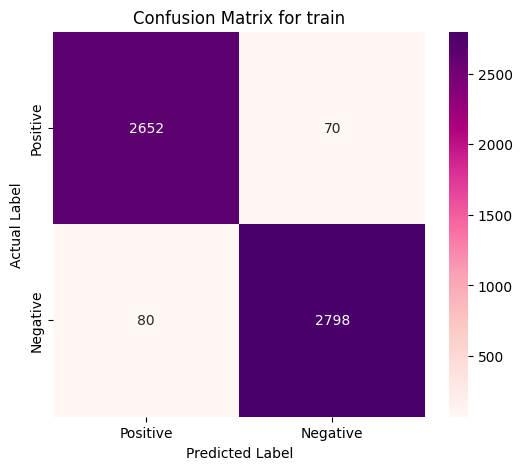


--- Classification Report ---
              precision    recall  f1-score   support

    Positive       0.97      0.97      0.97      2722
    Negative       0.98      0.97      0.97      2878

    accuracy                           0.97      5600
   macro avg       0.97      0.97      0.97      5600
weighted avg       0.97      0.97      0.97      5600



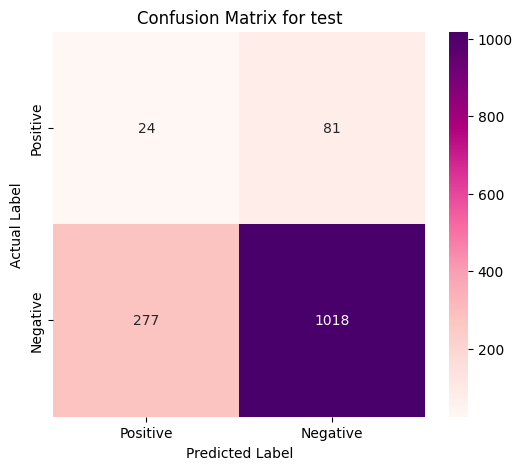


--- Classification Report ---
              precision    recall  f1-score   support

    Positive       0.08      0.23      0.12       105
    Negative       0.93      0.79      0.85      1295

    accuracy                           0.74      1400
   macro avg       0.50      0.51      0.48      1400
weighted avg       0.86      0.74      0.80      1400



In [ ]:
def plot_confusion_matrix(model, loader, device,mode):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            outputs = model(batch_x).squeeze()

            predictions = (torch.sigmoid(outputs) > 0.5).float()

            y_true.extend(batch_y.numpy())
            y_pred.extend(predictions.cpu().numpy())

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
                xticklabels=['Positive', 'Negative'],
                yticklabels=['Positive', 'Negative'])
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.title(f'Confusion Matrix for {mode}')
    plt.show()

    print("\n--- Classification Report ---")
    print(classification_report(y_true, y_pred, target_names=['Positive', 'Negative'], zero_division=0))
plot_confusion_matrix(model, train_loader, device ,"train")
plot_confusion_matrix(model, test_loader, device ,"test")